# code_051 · Outliers, corruption and rare events

**Book:** section 10.5. A self-contained data-cleaning laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_10_GUIDE.md), [run evidence](../CHAPTER_10_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_051).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Construction audits are distinct from predictive assessment; fitted examples declare training/development/final roles locally. All data and calibration/measurement assumptions are simulated, without field safety, causal or universal cleaning claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1051;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1051


<a id="trail"></a>
## Investigate a spike before calling it an outlier

A 160-day fixture has three nearby strain sensors responding to a known load series. Day 120 has a documented large load and a shared physical-response spike. Day 80 has a factor-1,000 unit-encoding fault in sensor 0 only, verified by its source payload. Agreement with neighbors is supporting context, not a proof: a real localized fault or a correlated instrument fault could violate that heuristic. Check timestamps/arrival, neighbor behavior, source unit/calibration and independent load evidence before deciding.

Preserve both events and the raw source values. Convert the verified unit fault, retain the valid heavy-load event and record the reason. This fixture supplies known provenance; no field safety assessment or governing strain law is validated.


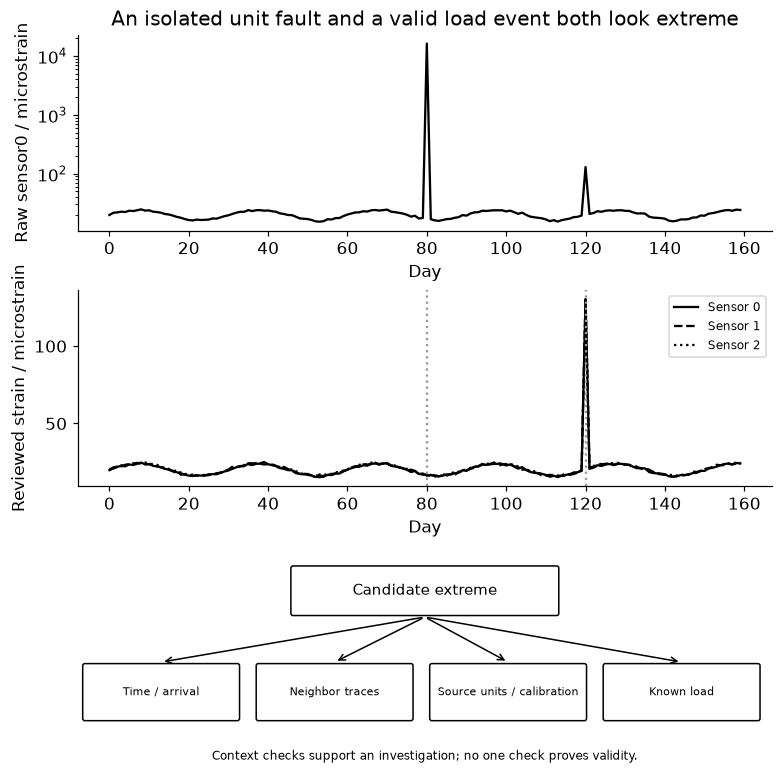

In [2]:
from matplotlib.patches import FancyBboxPatch,FancyArrowPatch
T=160;day=np.arange(T);load=10+2*np.sin(2*np.pi*day/30);load[120]=65
strain=np.array([2*load+rng.normal(0,.4,T)+j*.2 for j in range(3)]);raw=strain.copy();raw[0,80]*=1000;repaired=raw.copy();repaired[0,80]/=1000
assert np.allclose(repaired,strain) and raw[0,80]>1000 and repaired[0,120]>100
assert np.all(strain[:,120]>100) and np.all(strain[1:,80]<30)
audit={'day80':{'time':'aligned day80; arrival before use','neighbors':'no shared spike','source':'sensor0 payload declares 1000x numeric unit conversion','action':'convert verified source value; retain raw lineage'},'day120':{'time':'aligned day120','neighbors':'all three respond','source':'units/calibration unchanged','load':'known 65-kN event','action':'retain valid rare response'}}
fig,axes=plt.subplots(3,1,figsize=(7,7),gridspec_kw={'height_ratios':[1,1,1.15]})
axes[0].plot(day,raw[0],'k-');axes[0].set(yscale='log',xlabel='Day',ylabel='Raw sensor0 / microstrain',title='An isolated unit fault and a valid load event both look extreme')
for j,style in enumerate(['-','--',':']):axes[1].plot(day,repaired[j],ls=style,color='black',label=f'Sensor {j}')
axes[1].axvline(80,color='.6',ls=':');axes[1].axvline(120,color='.6',ls=':');axes[1].set(xlabel='Day',ylabel='Reviewed strain / microstrain');axes[1].legend(fontsize=8)
ax=axes[2];ax.axis('off');ax.set(xlim=(0,10),ylim=(0,3));ax.add_patch(FancyBboxPatch((3.1,2.1),3.8,.6,boxstyle='round,pad=.03',fc='white'));ax.text(5,2.4,'Candidate extreme',ha='center',va='center',fontsize=10)
for center,label in [(1.2,'Time / arrival'),(3.7,'Neighbor traces'),(6.2,'Source units / calibration'),(8.7,'Known load')]:
 ax.add_patch(FancyBboxPatch((center-1.1,.7),2.2,.7,boxstyle='round,pad=.03',fc='white'));ax.text(center,1.05,label,ha='center',va='center',fontsize=7.5,wrap=True);ax.add_patch(FancyArrowPatch((5,2.05),(center,1.45),arrowstyle='->',mutation_scale=10))
ax.text(5,.15,'Context checks support an investigation; no one check proves validity.',ha='center',fontsize=8);plt.show()
RESULTS['spike_audit']=audit;RESULTS['retained_valid_event_day']=120;RESULTS['verified_unit_fault_day']=80


<a id="fit"></a>
## Bound one residual's influence without declaring all extremes invalid

A separate regression fixture has 200 ordinary independent training members with normalized load in [0,1] and five valid high-load members in [2,2.5]. The response is .2+.8*load+noise sd .05 mm. One ordinary target is stored numerically in micrometres but consumed as millimetres, multiplying it by 1,000. Its actual source unit identifies the conversion before fitting. Compare predeclared raw OLS, fixed-delta Huber IRLS and verified-unit-repair OLS. All share [1,load] features. No tuning: Huber delta=.15 mm, at most 200 iterations and coefficient tolerance 1e-10. This is fixed residual-threshold Huber regression, not sklearn HuberRegressor's simultaneous scale estimate.

Huber loss is .5*r² within delta and delta*(abs(r)-.5*delta) outside. Its residual derivative saturates at +/-delta; extreme feature leverage can still matter. Use IRLS weights min(1,delta/abs(r)); no valid high-load member is removed. A blind three-standard-deviation rule on the correctly converted response flags valid rare members, showing why a statistical flag is not an origin diagnosis.


In [3]:
ordinary=200;high=5;train_load=np.r_[rng.uniform(0,1,ordinary),rng.uniform(2,2.5,high)];X=np.column_stack([np.ones(ordinary+high),train_load]);true_y=.2+.8*train_load+rng.normal(0,.05,len(train_load));bad_y=true_y.copy();bad_y[20]*=1000;fixed_y=bad_y.copy();fixed_y[20]/=1000
assert np.allclose(fixed_y,true_y) and train_load[20]<1
ols=np.linalg.lstsq(X,bad_y,rcond=None)[0];fixed=np.linalg.lstsq(X,fixed_y,rcond=None)[0];delta=.15
def huber_loss(r):return np.where(abs(r)<=delta,.5*r*r,delta*(abs(r)-.5*delta))
w=ols.copy();initial=float(huber_loss(bad_y-X@w).mean());steps=0
for steps in range(1,201):
 residual=bad_y-X@w;weight=np.minimum(1,delta/np.maximum(abs(residual),1e-15));new=np.linalg.lstsq(X*np.sqrt(weight[:,None]),bad_y*np.sqrt(weight),rcond=None)[0]
 change=np.max(abs(new-w));w=new
 if change<1e-10:break
assert steps<200 and np.max(abs(X.T@np.clip(bad_y-X@w,-delta,delta)))<1e-6
assert huber_loss(bad_y-X@w).mean()<=initial
blind=abs((fixed_y-fixed_y.mean())/fixed_y.std())>3;assert blind[ordinary:].any()
assert len(X)==205 and np.isfinite(w).all()
RESULTS['fitted_coefficients']={'raw_OLS':ols.tolist(),'Huber':w.tolist(),'verified_repair_OLS':fixed.tolist()};RESULTS['Huber_iterations']=steps;RESULTS['blind_rule_flagged_valid_high_load_members']=int(blind[ordinary:].sum());RESULTS['valid_high_load_members_retained']=high


<a id="final"></a>
## Assess the fixed procedures on ordinary and rare cases separately

A fresh final set has 100 ordinary and ten valid high-load members. All choices, source repairs and coefficients are frozen before its responses are assessed. Report overall and subgroup MAE for every procedure; no winner is used for further tuning. Known linear response favors this simple family, and robust improvement against one response corruption does not establish protection against all outliers or unseen mechanisms. The physical spike investigation and regression fixture are separate experiments.


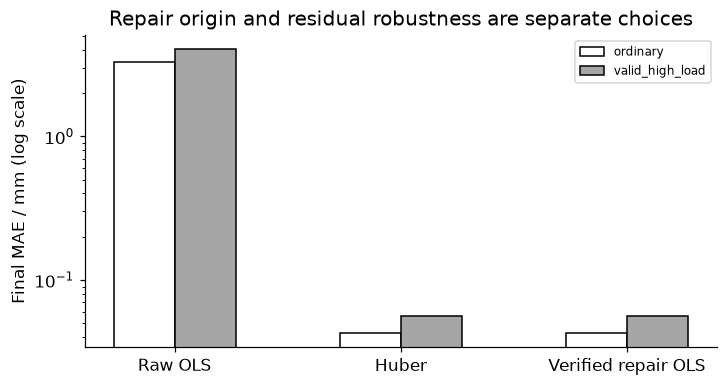

In [4]:
final_load=np.r_[rng.uniform(0,1,100),rng.uniform(2,2.5,10)];final_y=.2+.8*final_load+rng.normal(0,.05,110);XF=np.column_stack([np.ones(110),final_load]);models={'raw_OLS':ols,'Huber':w,'verified_repair_OLS':fixed}
metric={name:{'overall':float(np.mean(abs(XF@coef-final_y))),'ordinary':float(np.mean(abs((XF@coef-final_y)[:100]))),'valid_high_load':float(np.mean(abs((XF@coef-final_y)[100:])))} for name,coef in models.items()}
assert all(np.isfinite(list(v.values())).all() for v in metric.values())
fig,ax=plt.subplots(figsize=(6.5,3.4));xx=np.arange(3);width=.27
for j,(slice_name,shade) in enumerate([('ordinary','white'),('valid_high_load','.65')]):ax.bar(xx+(j-.5)*width,[metric[k][slice_name] for k in models],width,color=shade,edgecolor='black',label=slice_name)
ax.set(xticks=xx,xticklabels=['Raw OLS','Huber','Verified repair OLS'],yscale='log',ylabel='Final MAE / mm (log scale)',title='Repair origin and residual robustness are separate choices');ax.legend(fontsize=8);plt.show()
RESULTS['final_MAE_mm']=metric;RESULTS['final_counts']={'ordinary':100,'valid_high_load':10}


<a id="exercises"></a>
## Exercises and hints

1. Introduce a valid localized physical spike with no neighbor response. Explain why disagreement alone cannot prove corruption.
2. Change the response law at high loads; test whether a robust linear fit downweights the phenomenon the task needs.
3. Corrupt an extreme input rather than a target and examine Huber's leverage limitation.
4. Vary delta using training/development evidence and reserve new final cases for that revised procedure.

**Hints:** investigate origin, preserve raw values and record the correction rationale. Robust fitting limits a residual contribution under a chosen model; it does not classify physical events as valid or invalid. The original Huber loss motivates the mechanism, while the [official robust-regression discussion](https://scikit-learn.org/1.9/modules/linear_model.html#huber-regression) describes a different fitted-scale implementation. Neither one unit repair nor this fixed-threshold experiment is a general cleaning benchmark.


In [5]:
summary={'example_id':'code_051','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['provenance-led investigation of extreme strain', 'known loading event versus isolated source-unit fault', 'blind outlier deletion erases valid rare cases', 'fixed-threshold Huber response robustness', 'verified repair and independent final assessment'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["provenance-led investigation of extreme strain", "known loading event versus isolated source-unit fault", "blind outlier deletion erases valid rare cases", "fixed-threshold Huber response robustness", "verified repair and independent final assessment"], "elapsed_seconds": 0.269, "example_id": "code_051", "hardware": "Darwin arm64 CPU", "results": {"Huber_iterations": 6, "blind_rule_flagged_valid_high_load_members": 5, "final_MAE_mm": {"Huber": {"ordinary": 0.04267696752971555, "overall": 0.04388473881748735, "valid_high_load": 0.05596245169520524}, "raw_OLS": {"ordinary": 3.313611615850096, "overall": 3.381644184003581, "valid_high_load": 4.061969865538424}, "verified_repair_OLS": {"ordinary": 0.0427690376133826, "overall": 0.043959975011618274, "valid_high_load": 0.05586934899397507}}, "final_counts": {"ordinary": 100, "valid_high_load": 10}, "fitted_coefficients": {"Huber": [0.19054346699215993, 0.8047418062782723], "raw_OLS": [3.283